# EM Beyond the Gaussian Mixture: Regressions and Images

This is the second Lecture 16 notebook. The teaching notebook
`gaussian-mixture-em` fitted Gaussian components to 392 cars. Here the
algorithm stays the same, the E-step is still Bayes' rule and the M-step is
still a weighted fit, and only the component model changes.

* **Part A. Mixtures of regressions.** Each component is a regression of
  $y$ on $x$. For linear regression the weighted fit is weighted least
  squares, a closed form; for logistic regression it has no closed form, and
  the M-step becomes a few gradient or Newton steps (generalized EM).
* **Part B. A mixture of Bernoullis on MNIST.** Each component is a template
  of 784 pixel probabilities, fitted to 60,000 binarized digits. Its limits
  point to the continuous code of Lecture 17.

**Running the notebook.** NumPy and a little PyTorch on the CPU. Part A
takes about 20 seconds and Part B between half a minute and two minutes on
an Apple M4 Pro. Run the cells in order; each part starts with its own setup
cell. Reading: ISLP Chapter 12; Bishop, *Pattern Recognition and Machine
Learning*, §9.3.3 and §14.5.


# Part A. Mixtures of Regressions

The Gaussian mixture of Lecture 16 is one instance of the general
latent-variable model $p_\theta(x,z)=p_\theta(z)\,p_\theta(x\mid z)$. This
part keeps the same algorithm and changes what each component is. A
component is now a **regression model**: it predicts a response $y$ from a
feature $x$, and the data are a mixture of subpopulations that follow
different regressions,
$$p_\theta(y\mid x)=\sum_{k=1}^K\pi_k\,p(y\mid x;\beta_k).$$

The E-step is Bayes' rule, exactly as before. The M-step is a **weighted
fit of each component's own model**, with the posteriors $\gamma_{ik}$ as
weights. Whether EM has a closed form therefore depends only on whether that
weighted fit does:

| component model | weighted fit in the M-step | closed form? |
|---|---|---|
| Gaussian | weighted mean and covariance | yes |
| linear regression | weighted least squares | yes |
| logistic regression | weighted logistic regression | **no** |

We will:

1. simulate two subpopulations that follow two different lines, and see a
   single least-squares line fail;
2. fit a mixture of linear regressions by EM, with a weighted-least-squares
   M-step checked against NumPy and scikit-learn;
3. look at a stationary point that is not a maximum, at restarts, and at
   label switching;
4. simulate two subpopulations that respond to $x$ in opposite directions,
   where a single logistic regression cannot fit the response curve;
5. fit a mixture of logistic regressions by **generalized EM**: the M-step
   takes gradient or Newton steps on $Q$ and stops early, and EM stays
   monotone as long as each M-step increases $Q$;
6. compare one gradient step, several gradient steps, and Newton steps per
   M-step; check the M-step against scikit-learn; break monotonicity with a
   step that is too large; and compare with gradient ascent on the marginal
   log likelihood by autograd.

Part B of the Lecture 16 teaching notebook `gaussian-mixture-em` verifies
$\nabla\ell(\theta_t)=\nabla_\theta Q(\theta\mid\theta_t)$ at $\theta=\theta_t$, the
identity behind everything in Section A5 below. Reading: Bishop, *Pattern
Recognition and Machine Learning*, §14.5 (mixtures of linear and logistic
regression models).

The first cell imports the libraries and fixes the seed. Nothing is
downloaded: every data set in this part is simulated, so we know the
true parameters and can check what EM recovers.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import torch
from scipy.special import expit, log_expit, logsumexp
from sklearn.linear_model import LinearRegression, LogisticRegression

NOTEBOOK_START = time.time()
SEED = 26519
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
COLORS = ['#00356B', '#7A3E47', '#5B7864', '#8C6D9E']
RGB = np.array([mcolors.to_rgb(c) for c in COLORS])
print('NumPy', np.__version__, ' PyTorch', torch.__version__)

NumPy 2.2.5  PyTorch 2.10.0


## A1. Two subpopulations, two lines

The simulation has $n=300$ observations with $x_i\sim\mathrm{Uniform}(0,10)$.
A hidden label decides which line produced $y_i$:
$$z_i=1\ (\text{probability }.6):\quad y_i=1+2x_i+\epsilon_i,\quad \epsilon_i\sim\mathcal N(0,1^2),$$
$$z_i=2\ (\text{probability }.4):\quad y_i=15-1.2x_i+\epsilon_i,\quad \epsilon_i\sim\mathcal N(0,1.5^2).$$
Think of two kinds of customer whose spending responds to price in opposite
directions. The lines cross at $x=4.375$. The cell simulates the data,
fits one least-squares line to all of it, and plots both. Look at the
residuals of the single line.

share of observations from line 2: 0.447
single least-squares line: y = 7.58 + 0.55 x,  R^2 = 0.099,  residual sd 4.93


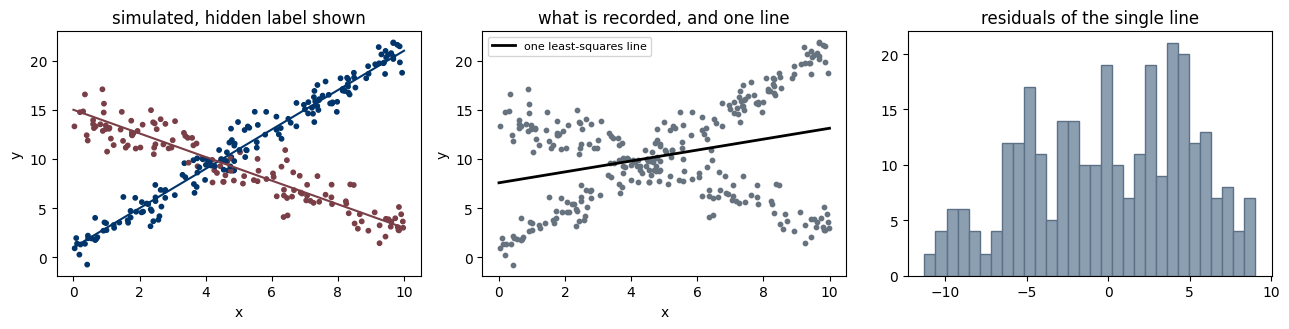

In [2]:
n = 300
x = rng.uniform(0, 10, n)
z = (rng.random(n) < .4).astype(int)                     # 0 = first line, 1 = second line
beta_true = np.array([[1.0, 2.0], [15.0, -1.2]])         # (intercept, slope) per component
sd_true = np.array([1.0, 1.5])
pi_true = np.array([.6, .4])
X = np.c_[np.ones(n), x]                                 # design matrix with an intercept column
y = (X * beta_true[z]).sum(axis=1) + sd_true[z] * rng.normal(size=n)

ols = np.linalg.lstsq(X, y, rcond=None)[0]
residual = y - X @ ols
print(f'share of observations from line 2: {z.mean():.3f}')
print(f'single least-squares line: y = {ols[0]:.2f} + {ols[1]:.2f} x,  R^2 = {1 - residual.var() / y.var():.3f},'
      f'  residual sd {residual.std():.2f}')

grid = np.linspace(0, 10, 2)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].scatter(x, y, s=10, c=RGB[z]); axes[0].set_title('simulated, hidden label shown')
for k in range(2):
    axes[0].plot(grid, beta_true[k, 0] + beta_true[k, 1] * grid, color=COLORS[k], lw=1.5)
axes[1].scatter(x, y, s=10, color='#66727E')
axes[1].plot(grid, ols[0] + ols[1] * grid, color='k', lw=2, label='one least-squares line')
axes[1].set_title('what is recorded, and one line'); axes[1].legend(fontsize=8)
axes[2].hist(residual, bins=30, color='#8C9FB1', edgecolor='#5C7186')
axes[2].set_title('residuals of the single line')
for ax in axes[:2]:
    ax.set(xlabel='x', ylabel='y')
plt.tight_layout(); plt.show()
assert 1 - residual.var() / y.var() < .2

Of the 300 observations, 44.7% come from the second line (the population
share is 40%). One least-squares line through everything is nearly flat,
$y=7.58+0.55x$, explains only 10% of the variance, and leaves residuals with
standard deviation 4.9, more than three times the noise of either true
line. Its residual histogram is spread out and lumpy, because each residual
mixes "which line" with "how much noise". The single line describes neither
subpopulation; it is the least-squares compromise between two that move in
opposite directions.

## A2. A mixture of linear regressions

The model treats the line as a hidden label:
$$\Pr(Z_i=k)=\pi_k,\qquad y_i\mid x_i,Z_i=k\;\sim\;\mathcal N\bigl(\beta_k^\top x_i,\;\sigma_k^2\bigr),$$
with $x_i=(1,x_i)$ including the intercept, and parameters
$\theta=(\pi_k,\beta_k,\sigma_k^2)_{k=1}^K$. Only the distribution of $y$
given $x$ is modelled; $x$ itself plays no role in the mixture.

**E-step.** Bayes' rule, with the regression likelihood in place of the
Gaussian density of Lecture 16:
$$\gamma_{ik}=\frac{\pi_k\,\mathcal N(y_i;\beta_k^\top x_i,\sigma_k^2)}{\sum_\ell\pi_\ell\,\mathcal N(y_i;\beta_\ell^\top x_i,\sigma_\ell^2)}.$$
A point is assigned by how close it lies to each **line**: a point near
the crossing at $x\approx4.4$ is ambiguous wherever its $y$ is.

The cell implements the E-step in log space and checks one responsibility
by hand, using the true parameters, for the observation at $x=8$,
$y=15$.

In [3]:
def gauss_logpdf(y, mean, variance):
    return -.5 * np.log(2 * np.pi * variance) - .5 * (y - mean) ** 2 / variance

def linear_e_step(X, y, weights, betas, variances):
    """Responsibilities (n x K) and the observed log likelihood sum_i log p(y_i | x_i)."""
    log_joint = np.log(weights)[None, :] + gauss_logpdf(y[:, None], X @ betas.T, variances[None, :])
    log_normalizer = logsumexp(log_joint, axis=1)
    return np.exp(log_joint - log_normalizer[:, None]), log_normalizer.sum()

# by hand: x = 8, y = 15 under the true parameters
line_means = beta_true[:, 0] + beta_true[:, 1] * 8                     # 17.0 and 5.4
numerators = pi_true * np.exp(-(15 - line_means) ** 2 / (2 * sd_true ** 2)) / sd_true
print('line values at x = 8:', line_means, '  gamma by hand:', np.round(numerators / numerators.sum(), 6))
gamma_code, _ = linear_e_step(np.array([[1.0, 8.0]]), np.array([15.0]), pi_true, beta_true, sd_true ** 2)
print('gamma from linear_e_step:', np.round(gamma_code[0], 6))
assert np.allclose(gamma_code[0], numerators / numerators.sum())

line values at x = 8: [17.   5.4]   gamma by hand: [1. 0.]
gamma from linear_e_step: [1. 0.]


At $x=8$ the two lines predict 17.0 and 5.4. The observation $y=15$ is
two standard deviations below the first line and 6.4 standard deviations
above the second, so it belongs to line 1 with probability essentially 1
(the second posterior is about $4\times10^{-9}$). The hand formula, with the
common $1/\sqrt{2\pi}$ cancelled, and the log-space code agree to every
printed digit.

**M-step.** With the $\gamma_{ik}$ fixed, the part of
$Q(\theta\mid\theta^{(t)})$ that involves $\beta_k$ is
$$-\frac1{2\sigma_k^2}\sum_i\gamma_{ik}\,(y_i-\beta_k^\top x_i)^2,$$
a **weighted least-squares** problem. Setting its gradient to zero gives
weighted normal equations, and the variance and weight follow as in
Lecture 16:
$$\beta_k=\bigl(X^\top\Gamma_kX\bigr)^{-1}X^\top\Gamma_ky,\qquad
\sigma_k^2=\frac1{N_k}\sum_i\gamma_{ik}(y_i-\beta_k^\top x_i)^2,\qquad
\pi_k=\frac{N_k}n,$$
with $\Gamma_k=\mathrm{diag}(\gamma_{1k},\ldots,\gamma_{nk})$ and
$N_k=\sum_i\gamma_{ik}$. The cell solves the weighted normal equations for
one arbitrary set of weights and checks the answer two other ways: ordinary
least squares on rows scaled by $\sqrt{\gamma_{ik}}$, and scikit-learn's
`LinearRegression(...).fit(..., sample_weight=...)`.

In [4]:
def linear_m_step(X, y, gamma):
    counts = gamma.sum(axis=0)
    betas = np.stack([np.linalg.solve(X.T @ (gamma[:, k, None] * X), X.T @ (gamma[:, k] * y))
                      for k in range(gamma.shape[1])])
    variances = np.array([(gamma[:, k] * (y - X @ betas[k]) ** 2).sum() / counts[k]
                          for k in range(gamma.shape[1])])
    return counts / len(y), betas, variances

weights_test = rng.random(n)                                            # any nonnegative weights
normal_eq = linear_m_step(X, y, np.c_[weights_test, 1 - weights_test])[1][0]
root = np.sqrt(weights_test)
scaled = np.linalg.lstsq(root[:, None] * X, root * y, rcond=None)[0]
library = LinearRegression().fit(x[:, None], y, sample_weight=weights_test)
print('weighted normal equations:', normal_eq.round(6))
print('lstsq on sqrt-weighted rows:', scaled.round(6))
print('scikit-learn sample_weight: ', np.r_[library.intercept_, library.coef_].round(6))
assert np.allclose(normal_eq, scaled) and np.allclose(normal_eq, np.r_[library.intercept_, library.coef_])

weighted normal equations: [7.583111 0.533971]
lstsq on sqrt-weighted rows: [7.583111 0.533971]
scikit-learn sample_weight:  [7.583111 0.533971]


All three agree to six decimals. Scaling row $i$ by $\sqrt{\gamma_{ik}}$
turns $\sum_i\gamma_{ik}(y_i-\beta^\top x_i)^2$ into an ordinary sum of
squares, which is why any least-squares solver can serve as the M-step. The
M-step of a mixture of regressions is "run your regression with sample
weights", once per component.

**The EM loop.** We start from random responsibilities (each row a
draw from a uniform Dirichlet), run an M-step to get parameters, and then
alternate. The cell records the observed log likelihood
$\ell(\theta)=\sum_i\log p_\theta(y_i\mid x_i)$, asserts that it never
decreases, and draws the two fitted lines at iterations 0, 1, 3 and 50
with each point coloured by its $\gamma_{i1}$. Look at how long the run
stays near its starting value before the lines separate.

log likelihood at iterations 0, 1, 2, 5, 10, 99: [-904.21 -903.97 -903.03 -859.73 -646.17 -646.17]
smallest change between iterations: -2.3e-13


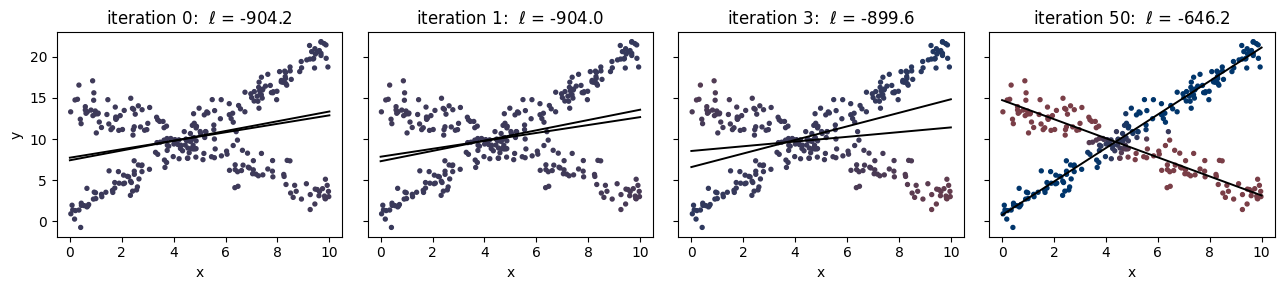

In [5]:
def linear_em(X, y, K=2, seed=0, steps=100, gamma=None):
    start = np.random.default_rng(seed)
    if gamma is None:
        gamma = start.dirichlet(np.ones(K), size=len(y))
    weights, betas, variances = linear_m_step(X, y, gamma)
    history = []
    for _ in range(steps):
        gamma, loglik = linear_e_step(X, y, weights, betas, variances)
        history.append({'loglik': loglik, 'betas': betas.copy(), 'gamma': gamma})
        weights, betas, variances = linear_m_step(X, y, gamma)
    return {'weights': weights, 'betas': betas, 'variances': variances, 'gamma': gamma,
            'loglik': np.array([h['loglik'] for h in history]), 'history': history}

fit = linear_em(X, y, seed=SEED)
print('log likelihood at iterations 0, 1, 2, 5, 10, 99:', np.round(fit['loglik'][[0, 1, 2, 5, 10, 99]], 2))
print(f'smallest change between iterations: {np.diff(fit["loglik"]).min():.1e}')

fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, t in zip(axes, [0, 1, 3, 50]):
    snap = fit['history'][t]
    ax.scatter(x, y, s=8, c=snap['gamma'] @ RGB[:2])
    for k in range(2):
        ax.plot(grid, snap['betas'][k, 0] + snap['betas'][k, 1] * grid, color='k', lw=1.4)
    ax.set(title=f'iteration {t}:  $\\ell$ = {snap["loglik"]:.1f}', xlabel='x')
axes[0].set_ylabel('y')
plt.tight_layout(); plt.show()
assert np.diff(fit['loglik']).min() > -1e-8

Random responsibilities are close to $\tfrac12$ for every point, so the
first M-step fits two almost identical, nearly flat lines, and the log
likelihood starts at $-904.2$, almost the single-line value. EM lingers
there for a few iterations ($-904.0$ and $-903.0$ at iterations 1 and 2)
because it starts next to the symmetric stationary point examined in
Section A3. Once the small asymmetry has grown, one line tilts up and the
other down, the colours separate, and the log likelihood jumps to $-859.7$
at iteration 5 and $-646.17$ at iteration 10, where it stays. No change is
negative beyond rounding ($2\times10^{-13}$). The only points that stay mixed in colour
are the ones near the crossing, where both lines predict about the same
$y$.

## A3. A stationary point that is not a maximum, restarts, and label switching

If both components start **identical**, the E-step gives every point
$\gamma_{i1}=\gamma_{i2}=\tfrac12$, the M-step then fits the same weighted
line twice, and the components stay identical forever. EM's fixed point
there is the single least-squares line, and its log likelihood is the
single-line value. It is a stationary point of $\ell$ that is not a maximum.
The cell runs EM from that start, and then from twenty random starts.

In [6]:
symmetric = linear_em(X, y, gamma=np.full((n, 2), .5), steps=50)
single_sigma2 = residual.var()
single_loglik = gauss_logpdf(y, X @ ols, single_sigma2).sum()
print('symmetric start, final lines:', symmetric['betas'].round(3).tolist())
print(f'symmetric start, final log likelihood {symmetric["loglik"][-1]:.2f};'
      f'  one Gaussian regression line: {single_loglik:.2f}')

runs = [linear_em(X, y, seed=SEED + r) for r in range(20)]
finals = np.array([run['loglik'][-1] for run in runs])
print('twenty random starts, final log likelihoods: min', finals.min().round(2), ' max', finals.max().round(2))
print('first fitted slope in the first five runs:', [round(float(run['betas'][0, 1]), 2) for run in runs[:5]])
assert np.allclose(symmetric['betas'][0], symmetric['betas'][1]) and abs(symmetric['loglik'][-1] - single_loglik) < 1e-6
assert finals.max() - finals.min() < 1e-3

symmetric start, final lines: [[7.582, 0.554], [7.582, 0.554]]
symmetric start, final log likelihood -904.29;  one Gaussian regression line: -904.29


twenty random starts, final log likelihoods: min -646.17  max -646.17
first fitted slope in the first five runs: [2.03, -1.16, 2.03, 2.03, -1.16]


From the symmetric start EM returns the single least-squares line twice
($7.58+0.55x$), with log likelihood $-904.29$, exactly the likelihood of
one Gaussian regression. That point is 258 nats below the fitted
mixture (a nat is the unit of a natural-log likelihood: a difference of
$\Delta$ nats is a factor $e^{\Delta}$ in the probability of the data, so 258
nats is a factor of about $10^{112}$; see the box below), yet EM never leaves it, because the gradient there is zero. Random
starts break the symmetry, and on this well-separated simulation all twenty
reach the same maximum, $-646.17$. They do not agree on the **names**: in
some runs component 1 is the rising line (slope about $2.0$), in others
it is the falling one (slope about $-1.2$). Relabelling leaves the likelihood
unchanged, so components must be matched to each other, or to the truth,
by their parameters.

**The unit: nats.** Log likelihoods here use the natural logarithm, and a
quantity measured that way is in **nats** (in bits with $\log_2$;
1 nat $=1/\ln2\approx1.44$ bits). Read differences: $\Delta$ nats higher
means the data are $e^{\Delta}$ times as probable, so 1 nat is a factor of
$e\approx2.7$ and 10 nats a factor of about 22,000. A gap of 0.01 nats, the
tolerance used below, is a factor of 1.01: two fits that close are equally
good for any practical purpose.

**What EM recovered.** The cell orders the best run's components by
slope (rising line first) and sets them beside the truth. It also
classifies each observation by its largest $\gamma_{ik}$ and compares with
the hidden label, which the fit never saw.

In [7]:
best = runs[int(finals.argmax())]
order = np.argsort(-best['betas'][:, 1])
recovered = pd.DataFrame({
    'pi true': pi_true, 'pi hat': best['weights'][order],
    'intercept true': beta_true[:, 0], 'intercept hat': best['betas'][order, 0],
    'slope true': beta_true[:, 1], 'slope hat': best['betas'][order, 1],
    'sd true': sd_true, 'sd hat': np.sqrt(best['variances'][order])}, index=['line 1', 'line 2'])
display(recovered.round(3))
assigned = best['gamma'][:, order].argmax(axis=1)
print(f'largest-posterior line matches the hidden label for {(assigned == z).mean():.1%} of observations')
near_crossing = np.abs(x - 4.375) < .75
print(f'accuracy within 0.75 of the crossing: {(assigned == z)[near_crossing].mean():.1%} '
      f'({near_crossing.sum()} points);  elsewhere: {(assigned == z)[~near_crossing].mean():.1%}')
assert np.allclose(best['betas'][order], beta_true, atol=.4)

,pi true,pi hat,intercept true,intercept hat,slope true,slope hat,sd true,sd hat
line 1,0.6,0.534,1.0,0.774,2.0,2.035,1.0,1.053
line 2,0.4,0.466,15.0,14.737,-1.2,-1.159,1.5,1.336


largest-posterior line matches the hidden label for 93.0% of observations
accuracy within 0.75 of the crossing: 64.2% (53 points);  elsewhere: 99.2%


The slopes and intercepts are recovered closely: the rising line is
$0.77+2.03x$ (truth $1+2x$) and the falling line $14.74-1.16x$ (truth
$15-1.2x$), with noise standard deviations 1.05 and 1.34 against 1 and 1.5.
The estimated weights, $(.53,.47)$, track this sample's shares
$(.553,.447)$ more closely than the population's $(.6,.4)$, as they should:
the weights are estimated from these 300 points. The largest posterior
recovers the hidden label for 93.0% of observations overall and 99.2% of
those farther than 0.75 from the crossing. For the 53 points near the
crossing, where the two lines predict almost the same $y$, the label is
genuinely uncertain and the accuracy is 64.2%. Every
step of this section had a closed form.

## A4. Two subpopulations that respond in opposite directions

Now the response is binary. Each observation has a dose $x_i\sim\mathcal N(0,1.5^2)$
and an outcome $y_i\in\{0,1\}$, and the population contains two kinds of
individual:
$$z_i=1\ (\text{probability }.65):\quad \Pr(y_i=1\mid x_i)=\sigma(-4+4x_i),$$
$$z_i=2\ (\text{probability }.35):\quad \Pr(y_i=1\mid x_i)=\sigma(-4-4x_i),$$
where $\sigma(t)=1/(1+e^{-t})$. The first kind responds once the dose
exceeds 1; the second responds once it falls below $-1$. Averaging over the
hidden kind, $\Pr(y=1\mid x)$ is about .35 for very negative doses, near 0
between $-1$ and $1$, and about .65 for large doses: a U-shaped curve.

The cell simulates $n=8{,}000$ observations, fits one logistic regression,
and plots the observed response rate in bins of $x$ against the truth and
the single fit.

response rate 0.265;  share of kind 2 0.349
single logistic regression: intercept -1.072, slope 0.335,  log likelihood -4441.2


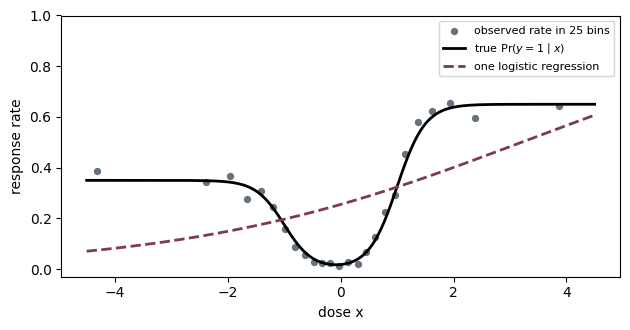

In [8]:
n2 = 8000
dose = rng.normal(0, 1.5, n2)
kind = (rng.random(n2) < .35).astype(int)
beta_logit_true = np.array([[-4.0, 4.0], [-4.0, -4.0]])
pi_logit_true = np.array([.65, .35])
Xd = np.c_[np.ones(n2), dose]
outcome = (rng.random(n2) < expit((Xd * beta_logit_true[kind]).sum(axis=1))).astype(float)

def true_curve(t):
    return pi_logit_true @ expit(beta_logit_true[:, :1] + beta_logit_true[:, 1:] * t[None, :])

def bernoulli_loglik(y, p):
    return (y * np.log(p) + (1 - y) * np.log1p(-p)).sum()

single = LogisticRegression(penalty=None).fit(dose[:, None], outcome)
p_single = single.predict_proba(dose[:, None])[:, 1]
print(f'response rate {outcome.mean():.3f};  share of kind 2 {kind.mean():.3f}')
print(f'single logistic regression: intercept {single.intercept_[0]:.3f}, slope {single.coef_[0, 0]:.3f},'
      f'  log likelihood {bernoulli_loglik(outcome, p_single):.1f}')

edges = np.quantile(dose, np.linspace(0, 1, 26))
centers = .5 * (edges[1:] + edges[:-1])
rates = [outcome[(dose >= a) & (dose < b)].mean() for a, b in zip(edges[:-1], edges[1:])]
t = np.linspace(-4.5, 4.5, 300)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.scatter(centers, rates, color='#66727E', s=18, label='observed rate in 25 bins')
ax.plot(t, true_curve(t), color='k', lw=2, label='true $\\Pr(y=1\\mid x)$')
ax.plot(t, single.predict_proba(t[:, None])[:, 1], color=COLORS[1], lw=2, ls='--', label='one logistic regression')
ax.set(xlabel='dose x', ylabel='response rate', ylim=(-.03, 1)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
assert abs(single.coef_[0, 0]) < 1

The binned response rates trace the U shape: about a third of the
lowest-dose individuals respond, almost nobody between $-1$ and $1$, and
roughly two-thirds at the highest doses. A single logistic regression is
monotone in $x$ by construction; the best it can do is a shallow upward
tilt (slope 0.34) that misses both arms and predicts a substantial
response in the middle, where there is almost none. As with the two lines,
the single model averages two subpopulations that move in opposite
directions.

## A5. A mixture of logistic regressions, fitted by generalized EM

The model is
$$\Pr(Z_i=k)=\pi_k,\qquad \Pr(y_i=1\mid x_i,Z_i=k)=\sigma(\beta_k^\top x_i).$$

**E-step.** Unchanged in form: Bayes' rule with Bernoulli likelihoods,
$\gamma_{ik}\propto\pi_k\,\sigma(\beta_k^\top x_i)^{y_i}\bigl(1-\sigma(\beta_k^\top x_i)\bigr)^{1-y_i}$.

**M-step.** $\pi_k=N_k/n$ as always. For $\beta_k$ we must maximize
$$Q_k(\beta)=\sum_i\gamma_{ik}\Bigl[y_i\log\sigma(\beta^\top x_i)+(1-y_i)\log\bigl(1-\sigma(\beta^\top x_i)\bigr)\Bigr],$$
a **weighted logistic regression**. It is concave in $\beta$, but setting the
gradient to zero gives
$$\nabla Q_k(\beta)=\sum_i\gamma_{ik}\bigl(y_i-\sigma(\beta^\top x_i)\bigr)x_i=0,$$
which has no closed-form solution: $\beta$ sits inside the sigmoid. This
is the first model in the course where EM's M-step must itself be an
iterative optimization.

**Generalized EM.** The monotonicity proof of the deck needed only
$\mathcal L(q^{(t+1)},\theta^{(t+1)})\ge\mathcal L(q^{(t+1)},\theta^{(t)})$,
that is, that the M-step **increases** $Q$. Maximizing $Q$ is one way to do
that; a few ascent steps that increase $Q$ are another, and the chain of
inequalities still holds. The two standard choices:

* **gradient ascent:** $\beta_k\leftarrow\beta_k+\eta\,\nabla Q_k(\beta_k)$. The
  curvature of $Q_k$ is bounded by $\tfrac14X^\top\Gamma_kX$, since
  $\sigma'(t)\le\tfrac14$; the step $\eta=4/\lambda_{\max}(X^\top\Gamma_kX)$
  therefore never decreases $Q_k$;
* **Newton (iteratively reweighted least squares):**
  $\beta_k\leftarrow\beta_k+H_k^{-1}\nabla Q_k$ with
  $H_k=\sum_i\gamma_{ik}\,p_i(1-p_i)\,x_ix_i^\top$. Much faster near the
  optimum, with no guarantee of increase far from it, so we halve the step
  until $Q_k$ increases.

The next cell implements the E-step, the weighted log likelihood $Q_k$, and
both M-step updates.

In [9]:
def logistic_e_step(X, y, weights, betas):
    eta = X @ betas.T                                                  # n x K linear predictors
    log_lik = y[:, None] * log_expit(eta) + (1 - y[:, None]) * log_expit(-eta)
    log_joint = np.log(weights)[None, :] + log_lik
    log_normalizer = logsumexp(log_joint, axis=1)
    return np.exp(log_joint - log_normalizer[:, None]), log_normalizer.sum()

def weighted_q(X, y, g, beta):
    eta = X @ beta
    return (g * (y * log_expit(eta) + (1 - y) * log_expit(-eta))).sum()

def gradient_step(X, y, g, beta):
    eta_max = 4 / np.linalg.eigvalsh(X.T @ (g[:, None] * X)).max()      # 1 / (curvature bound)
    return beta + eta_max * X.T @ (g * (y - expit(X @ beta)))

def newton_step(X, y, g, beta, damped=True):
    p = expit(X @ beta)
    grad = X.T @ (g * (y - p))
    hessian = X.T @ ((g * p * (1 - p))[:, None] * X) + 1e-10 * np.eye(X.shape[1])
    step = np.linalg.solve(hessian, grad)
    if not damped:
        return beta + step
    q0, scale = weighted_q(X, y, g, beta), 1.0
    while weighted_q(X, y, g, beta + scale * step) < q0 and scale > 1e-8:
        scale /= 2                                                     # backtrack until Q_k increases
    return beta + scale * step

# One M-step update from a fixed start, for one component with random weights:
g_demo = rng.random(n2)
beta0 = np.array([0.0, 0.5])
rows = [{'update': 'start', 'Q_k': weighted_q(Xd, outcome, g_demo, beta0)}]
b = beta0.copy()
for s in range(3):
    b = gradient_step(Xd, outcome, g_demo, b)
    rows.append({'update': f'gradient step {s + 1}', 'Q_k': weighted_q(Xd, outcome, g_demo, b)})
b = beta0.copy()
for s in range(3):
    b = newton_step(Xd, outcome, g_demo, b)
    rows.append({'update': f'Newton step {s + 1}', 'Q_k': weighted_q(Xd, outcome, g_demo, b)})
display(pd.DataFrame(rows).round(3))

,update,Q_k
0,start,-2751.777
1,gradient step 1,-2385.517
2,gradient step 2,-2275.320
3,gradient step 3,-2235.374
4,Newton step 1,-2216.338
5,Newton step 2,-2206.207
6,Newton step 3,-2206.187


Each gradient step raises $Q_k$, and so does each Newton step, by
more. Three Newton steps have essentially reached the maximum of this
weighted logistic regression; three gradient steps are still below it.
Either kind of step is enough for generalized EM, as long as $Q_k$ goes up.

**Checking the M-step against scikit-learn.** At convergence, our Newton
iterations should solve the same weighted logistic regression that
`LogisticRegression(penalty=None).fit(X, y, sample_weight=g)` solves. The
cell runs 25 Newton steps and compares.

In [10]:
b = beta0.copy()
for _ in range(25):
    b = newton_step(Xd, outcome, g_demo, b)
library = LogisticRegression(penalty=None, tol=1e-10, max_iter=10_000).fit(dose[:, None], outcome, sample_weight=g_demo)
library_beta = np.r_[library.intercept_, library.coef_[0]]
print('25 Newton steps:          ', b.round(6))
print('scikit-learn sample_weight:', library_beta.round(6))
print(f'largest gradient component at our solution: {np.abs(Xd.T @ (g_demo * (outcome - expit(Xd @ b)))).max():.1e}')
assert np.allclose(b, library_beta, atol=1e-4)

25 Newton steps:           [-1.092655  0.336782]
scikit-learn sample_weight: [-1.092655  0.336782]
largest gradient component at our solution: 3.3e-14


The two solutions agree to at least four decimals, and the gradient
of $Q_k$ at ours is zero to machine precision. So the M-step of a mixture
of logistic regressions is exactly "fit a logistic regression with sample
weights $\gamma_{ik}$" for each component, the same recipe as Section A2
with a regression that needs an iterative solver.

**Generalized EM, four ways.** The cell runs EM for 300 iterations with
four M-steps: one gradient step, five gradient steps, fifty gradient steps,
and one damped Newton step. All four start from the same parameters. It
records the log likelihood, asserts monotonicity, and reports how many
iterations and how much time each needs to come within 0.01 nats of the
best value found.

,M-step,final log likelihood,smallest change,iterations to within .01,seconds to within .01
0,1 gradient step,-3567.2748,0.0305,NaN,NaN
1,5 gradient steps,-3564.2208,0.0001,237.0,0.7431
2,50 gradient steps,-3564.2180,-0.0000,34.0,0.6835
3,1 Newton step,-3564.2180,-0.0000,35.0,0.0951


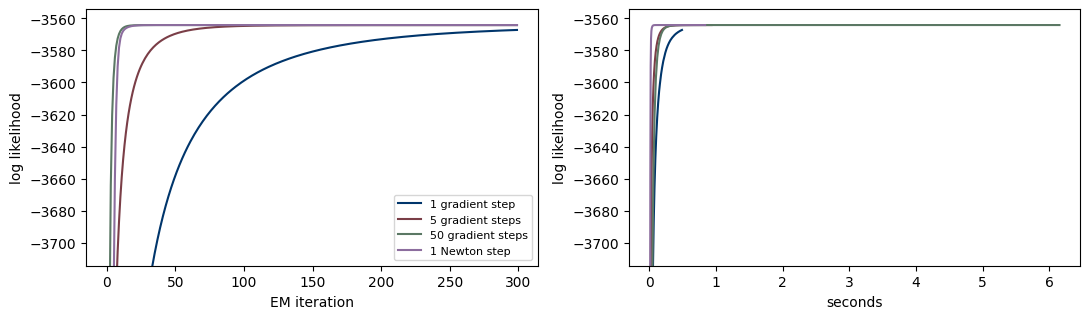

In [11]:
def logistic_em(X, y, m_step='gradient', inner=1, steps=300, seed=0, damped=True):
    start = np.random.default_rng(seed)
    betas, weights = start.normal(0, 1, (2, X.shape[1])), np.array([.5, .5])
    loglik, times = [], []
    clock = time.perf_counter()
    for _ in range(steps):
        gamma, value = logistic_e_step(X, y, weights, betas)
        loglik.append(value); times.append(time.perf_counter() - clock)
        weights = gamma.mean(axis=0)
        for k in range(2):
            for _ in range(inner):
                if m_step == 'gradient':
                    betas[k] = gradient_step(X, y, gamma[:, k], betas[k])
                else:
                    betas[k] = newton_step(X, y, gamma[:, k], betas[k], damped=damped)
    return {'weights': weights, 'betas': betas, 'gamma': gamma,
            'loglik': np.array(loglik), 'time': np.array(times)}

variants = {'1 gradient step': ('gradient', 1), '5 gradient steps': ('gradient', 5),
            '50 gradient steps': ('gradient', 50), '1 Newton step': ('newton', 1)}
results = {name: logistic_em(Xd, outcome, m_step=kind_, inner=inner, seed=1) for name, (kind_, inner) in variants.items()}
target = max(r['loglik'].max() for r in results.values())
rows = []
for name, r in results.items():
    reached = np.flatnonzero(r['loglik'] > target - .01)
    rows.append({'M-step': name, 'final log likelihood': r['loglik'][-1],
                 'smallest change': np.diff(r['loglik']).min(),
                 'iterations to within .01': reached[0] if len(reached) else np.nan,
                 'seconds to within .01': r['time'][reached[0]] if len(reached) else np.nan})
display(pd.DataFrame(rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
for (name, r), color in zip(results.items(), COLORS):
    axes[0].plot(r['loglik'], color=color, label=name)
    axes[1].plot(r['time'], r['loglik'], color=color, label=name)
for ax in axes:
    ax.set(ylabel='log likelihood', ylim=(target - 150, target + 10))
axes[0].set(xlabel='EM iteration'); axes[1].set(xlabel='seconds'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
for r in results.values():
    assert np.diff(r['loglik']).min() > -1e-6

All four variants increase the log likelihood at every iteration: the
smallest change is positive, or zero to four decimals once a run has
converged. The difference is speed. The damped Newton M-step and fifty
gradient steps per M-step both reach the maximum, $-3{,}564.22$, within 35
and 34 iterations; their M-steps are essentially exact, so they are
running textbook EM. Five gradient steps need 237 iterations. One gradient
step is still 3.1 nats short after 300 iterations, although it is still
climbing by at least 0.03 nats per iteration: an M-step that only climbs
$Q$ part of the way keeps EM monotone, and each EM iteration then achieves
less. In wall-clock time the picture changes: Newton needs 0.10 s, while
fifty gradient steps (0.68 s) and five (0.74 s) cost about the same, one
by doing more work per iteration and the other by needing more iterations.
The choice of inner solver is a trade-off between cost per M-step and the
number of outer iterations.

**What the fit recovered.** The next cell orders the components by slope,
compares them with the truth, and draws the fitted response curve with its
two components.

,pi true,pi hat,intercept true,intercept hat,slope true,slope hat
kind 1 (rises),0.65,0.639,-4.0,-4.245,4.0,4.500
kind 2 (falls),0.35,0.361,-4.0,-4.013,-4.0,-3.771


log likelihood: mixture -3564.2,  single logistic -4441.2


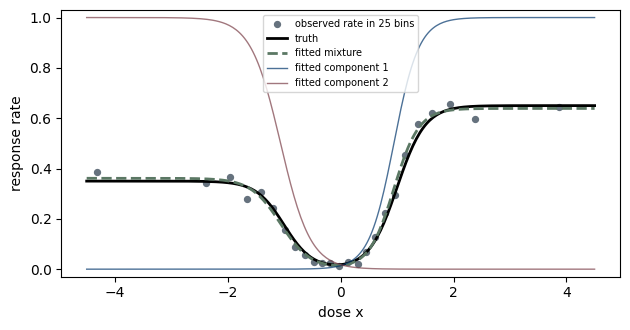

In [12]:
fitted = results['1 Newton step']
order = np.argsort(-fitted['betas'][:, 1])
table = pd.DataFrame({'pi true': pi_logit_true, 'pi hat': fitted['weights'][order],
                      'intercept true': beta_logit_true[:, 0], 'intercept hat': fitted['betas'][order, 0],
                      'slope true': beta_logit_true[:, 1], 'slope hat': fitted['betas'][order, 1]},
                     index=['kind 1 (rises)', 'kind 2 (falls)'])
display(table.round(3))
mixture_p = fitted['weights'] @ expit(fitted['betas'] @ Xd.T)
print(f'log likelihood: mixture {bernoulli_loglik(outcome, mixture_p):.1f},'
      f'  single logistic {bernoulli_loglik(outcome, p_single):.1f}')

curves = expit(fitted['betas'][order] @ np.c_[np.ones_like(t), t].T)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.scatter(centers, rates, color='#66727E', s=18, label='observed rate in 25 bins')
ax.plot(t, true_curve(t), color='k', lw=2, label='truth')
ax.plot(t, fitted['weights'][order] @ curves, color=COLORS[2], lw=2, ls='--', label='fitted mixture')
for k in range(2):
    ax.plot(t, curves[k], color=COLORS[k], lw=1, alpha=.7, label=f'fitted component {k + 1}')
ax.set(xlabel='dose x', ylabel='response rate', ylim=(-.03, 1.03)); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
assert np.allclose(fitted['betas'][order], beta_logit_true, atol=.6)
assert abs(fitted['weights'][order][0] - .65) < .05

The mixture recovers both subpopulations: weights $(.64,.36)$ against
$(.65,.35)$, and coefficients $(-4.25,4.50)$ and $(-4.01,-3.77)$ against
$(-4,4)$ and $(-4,-4)$. The remaining error is sampling noise: a binary
outcome carries little information about each observation's kind, which
is also why $n=8{,}000$ is used here. The mixture's log likelihood is 877
nats above the single logistic regression ($-3{,}564.2$ against
$-4{,}441.2$), and the fitted curve follows the U shape through the binned
rates. Each fitted component is an ordinary logistic curve; the U shape
comes from mixing two of them with the hidden kind integrated out.

**When the M-step overshoots.** Generalized EM needs each M-step to
increase $Q$. Two ways to violate that: a gradient step much larger than
$4/\lambda_{\max}$, and an undamped Newton step from a poor starting point.
The cell runs both, from the same starts as above, and prints the largest
decrease of the log likelihood in each run.

In [13]:
def logistic_em_fixed_lr(X, y, lr, steps=100, seed=1):
    start = np.random.default_rng(seed)
    betas, weights = start.normal(0, 1, (2, X.shape[1])), np.array([.5, .5])
    loglik = []
    for _ in range(steps):
        gamma, value = logistic_e_step(X, y, weights, betas)
        loglik.append(value); weights = gamma.mean(axis=0)
        for k in range(2):
            betas[k] = betas[k] + lr * X.T @ (gamma[:, k] * (y - expit(X @ betas[k])))
    return np.array(loglik)

safe = 4 / np.linalg.eigvalsh(Xd.T @ Xd).max()           # the bound with all weights equal to 1
rows = []
for multiple in [1, 5, 40]:
    path = logistic_em_fixed_lr(Xd, outcome, lr=multiple * safe)
    rows.append({'M-step': f'gradient, step {multiple} x the safe size', 'largest decrease': -np.diff(path).min(),
                 'final log likelihood': path[-1]})
for seed in range(4):
    path = logistic_em(Xd, outcome, m_step='newton', damped=False, steps=100, seed=seed)['loglik']
    rows.append({'M-step': f'undamped Newton, start {seed}', 'largest decrease': -np.diff(path).min(),
                 'final log likelihood': path[-1]})
overshoot = pd.DataFrame(rows)
display(overshoot.round(2))
assert overshoot['largest decrease'].max() > 1

,M-step,largest decrease,final log likelihood
0,"gradient, step 1 x the safe size",-1.29,-3664.03
1,"gradient, step 5 x the safe size",-0.13,-3568.86
2,"gradient, step 40 x the safe size",4524.16,-3564.71
3,"undamped Newton, start 0",-0.00,-3564.22
4,"undamped Newton, start 1",-0.00,-3564.22
5,"undamped Newton, start 2",-0.00,-3564.22
6,"undamped Newton, start 3",88.87,-3564.22


A negative entry in the "largest decrease" column means the log
likelihood rose at every iteration. With the safe step it always rose (by
at least 1.29 nats per iteration), and after 100 iterations it is still at
$-3{,}664$, 100 nats short of the maximum, because one conservative step per
M-step is slow. Five times the safe step still climbs at every iteration
on this problem, since the bound is conservative. Forty times overshoots:
the coefficients jump past the maximum of $Q_k$ and the log likelihood
drops by 4,524 nats in one iteration, before it happens to settle near the
maximum. Undamped Newton steps behave well from starts 0, 1 and 2, but from
start 3 an early step overshoots and the log likelihood falls by 88.9 nats;
that is why the Newton M-step above backtracks.
In every case the monotonicity theorem is intact; what failed is its
premise, that each M-step increases $Q$.

## A6. The same maximum by direct gradient ascent on $\ell$

EM is one way to maximize
$\ell(\theta)=\sum_i\log\sum_k\pi_k\,p(y_i\mid x_i;\beta_k)$. Another is to
hand $\ell$ to autograd and climb it directly, with no E-step at all.
Part B of `gaussian-mixture-em` shows why the two are close relatives:
at $\theta=\theta_t$ the gradient of $Q(\cdot\mid\theta_t)$ equals the
gradient of $\ell$, so one gradient-EM step is a gradient step on $\ell$.

The cell parametrizes the weights by a logit, $\pi_1=\sigma(a)$, so that
they stay in $(0,1)$, runs Adam on $-\ell/n$ for 3,000 full-batch steps from
the same start as the EM runs, and compares the answer with EM's.

In [14]:
X_t, y_t = torch.tensor(Xd), torch.tensor(outcome)
start = np.random.default_rng(1)
betas_t = torch.tensor(start.normal(0, 1, (2, 2)), requires_grad=True)
logit_t = torch.zeros(1, dtype=torch.float64, requires_grad=True)
optimizer = torch.optim.Adam([betas_t, logit_t], lr=.05)

def marginal_loglik(betas, logit):
    log_weights = torch.stack([torch.nn.functional.logsigmoid(logit), torch.nn.functional.logsigmoid(-logit)]).squeeze()
    eta = X_t @ betas.T
    log_lik = y_t[:, None] * torch.nn.functional.logsigmoid(eta) + (1 - y_t[:, None]) * torch.nn.functional.logsigmoid(-eta)
    return torch.logsumexp(log_weights[None, :] + log_lik, dim=1).sum()

clock = time.perf_counter()
for step in range(3000):
    optimizer.zero_grad()
    loss = -marginal_loglik(betas_t, logit_t) / n2
    loss.backward()
    optimizer.step()
seconds = time.perf_counter() - clock
direct_loglik = marginal_loglik(betas_t, logit_t).item()
direct_betas = betas_t.detach().numpy()
direct_weights = np.array([torch.sigmoid(logit_t).item(), 1 - torch.sigmoid(logit_t).item()])
o = np.argsort(-direct_betas[:, 1])
print(f'direct ascent: log likelihood {direct_loglik:.3f} after 3,000 Adam steps ({seconds:.1f} s)')
print(f'EM (Newton M-step): log likelihood {fitted["loglik"][-1]:.3f}')
print('direct ascent weights', direct_weights[o].round(3), ' coefficients', direct_betas[o].round(3).tolist())
print('EM weights           ', fitted['weights'][order].round(3), ' coefficients', fitted['betas'][order].round(3).tolist())
assert abs(direct_loglik - fitted['loglik'][-1]) < .05

direct ascent: log likelihood -3564.218 after 3,000 Adam steps (2.5 s)
EM (Newton M-step): log likelihood -3564.218
direct ascent weights [0.639 0.361]  coefficients [[-4.245, 4.5], [-4.013, -3.771]]
EM weights            [0.639 0.361]  coefficients [[-4.245, 4.5], [-4.013, -3.771]]


Adam on $\ell$ reaches the same log likelihood as EM, $-3{,}564.218$, and
the same weights and coefficients, to every printed decimal. Two maximizers of one objective agree. The practical differences
are elsewhere: EM needs no step size for $\pi$ and keeps it in the simplex
automatically, and each EM iteration is guaranteed to improve $\ell$; the
direct method needs a reparametrization of $\pi$ and a tuned learning rate,
and it is the method that survives when even the E-step has no closed form.

**Label switching and restarts.** The cell runs the Newton version of EM
from ten random starts and lists the final log likelihoods and the first
component's slope.

In [15]:
restarts = [logistic_em(Xd, outcome, m_step='newton', steps=150, seed=s) for s in range(10)]
summary = pd.DataFrame({'start': range(10),
                        'final log likelihood': [r['loglik'][-1] for r in restarts],
                        'component 1 slope': [r['betas'][0, 1] for r in restarts],
                        'component 1 weight': [r['weights'][0] for r in restarts]})
display(summary.round(3))
assert summary['final log likelihood'].max() - summary['final log likelihood'].min() < .01

,start,final log likelihood,component 1 slope,component 1 weight
0,0,-3564.218,-3.771,0.361
1,1,-3564.218,4.500,0.639
2,2,-3564.218,4.500,0.639
3,3,-3564.218,-3.771,0.361
4,4,-3564.218,-3.771,0.361
5,5,-3564.218,-3.771,0.361
6,6,-3564.218,4.500,0.639
7,7,-3564.218,4.500,0.639
8,8,-3564.218,-3.771,0.361
9,9,-3564.218,-3.771,0.361


All ten starts reach the same log likelihood, and "component 1" is the
rising kind (slope 4.50, weight .639) in some runs and the falling kind
(slope $-3.77$, weight .361) in others. As for the Gaussian
mixture, the labels carry no meaning of their own; on harder problems,
with more components or less separation, the final likelihoods also differ
and the best of several restarts is kept.

**A first mixture of experts.** Each component is an "expert" regression,
and $\pi_k$ decides how much each expert is trusted. Here the trust is the
same for every $x$. Letting it depend on $x$, $\pi_k(x)=\mathrm{softmax}_k(w_k^\top x)$
from a small "gating" model, gives the **mixture of experts**; its M-step
adds one more weighted fit, a multinomial logistic regression of the
$\gamma_{ik}$ on $x_i$, and has no closed form either. Mixture-of-experts
layers with a learned gate are used inside some of the largest language
models.

## A7. What stays the same, and where Lecture 17 goes

| model | E-step | M-step |
|---|---|---|
| Gaussian mixture | Bayes' rule over $K$ labels, closed form | weighted mean and covariance, closed form |
| mixture of linear regressions | Bayes' rule over $K$ labels, closed form | weighted least squares, closed form |
| mixture of logistic regressions | Bayes' rule over $K$ labels, closed form | weighted logistic regression, **iterative** (gradient or Newton steps) |
| variational autoencoder (Lecture 17) | posterior over a continuous code, **no closed form**: learned by an encoder | decoder network, **iterative** (gradient steps) |

Down the table, the objective is always the evidence lower bound
$\mathcal L(q,\theta)$, and the algorithm always alternates between
improving $q$ and improving $\theta$. In Part A only the M-step lost
its closed form, and a few ascent steps on $Q$ replaced it without losing
monotonicity. In the VAE the E-step loses its closed form too, because the
posterior over a continuous code passed through a network cannot be
written down. Both steps then become gradient steps on the same bound, taken
jointly.

## Summary of Part A

A mixture of regressions models data from hidden subpopulations that follow
different regressions. EM fits it with the same two steps as the Gaussian
mixture: Bayes' rule gives each observation a posterior share
$\gamma_{ik}$, and the M-step fits each component's own regression with
those shares as sample weights. For linear regressions the M-step is
weighted least squares, checked against NumPy and scikit-learn; EM recovers
the two crossing lines $1+2x$ and $15-1.2x$ from data where one
least-squares line explains 10% of the variance, and a symmetric start sits
forever at the single-line likelihood, a stationary point that is not a
maximum. For logistic regressions the M-step is a weighted logistic
regression with no closed form. Generalized EM replaces it by gradient or
Newton steps that increase $Q$; every variant was monotone and reached the
same maximum, recovering the U-shaped response of two opposite
subpopulations 877 nats better than a single logistic regression.
A step that overshoots $Q$ breaks monotonicity, and direct gradient ascent
on $\ell$ with autograd reaches the same maximum. Component labels switch
between restarts in both models.

## Try It: Part A

For each change, write down a prediction before rerunning the cells.

1. **Closer lines.** In Section A1, change the second line to $y=8+0.5x$.
   Predict whether the twenty restarts in Section A3 still agree, and how
   the accuracy away from the crossing changes.
2. **Three lines.** Add a third subpopulation $y=5+0.2x$ and fit with
   `K=3`. How many restarts reach the best likelihood now?
3. **Fewer observations.** In Section A4, set `n2 = 800`. Predict how far
   the recovered coefficients move from the truth, and whether the ten
   restarts still agree.
4. **Overlapping kinds.** Change the slopes to $\pm1$. The two logistic
   curves become shallow; does EM still separate the kinds, and how many
   iterations does the one-gradient-step M-step need?
5. **Step size.** In the overshoot cell, try multiples 2, 10 and 20 of the
   safe step. Where does monotonicity first fail?
6. **No intercept.** Drop the column of ones from `Xd`, so each component
   is $\sigma(\beta_kx_i)$. Which part of the U shape can the model no
   longer produce?

# Part B. A Mixture of Bernoullis on MNIST

The lecture fitted a Gaussian
mixture to 392 cars with two measurements each. Here the same algorithm runs on
60,000 handwritten digits with 784 binary pixels each: every car becomes an
image, every Gaussian component becomes a *template* of pixel probabilities,
and the E-step and M-step keep exactly the form derived in the slides. We will:

1. binarize MNIST and write the Bernoulli likelihood of an image as one matrix
   product;
2. compute a posterior $\gamma_{ik}$ by hand on three pixels, and see why the
   784-pixel version must be computed in log space;
3. derive the M-step, and see why a component needs **smoothing**, the
   analogue of the variance floor in the lecture;
4. run EM with $K=10$ and check that the objective never decreases;
5. verify the ELBO identity $\log p_\theta(x)=\mathcal L(q,\theta)+D_{\rm KL}(q\,\|\,p_\theta(z\mid x))$
   numerically on all 60,000 images;
6. compare the fitted components with the digit labels the model never saw,
   look at the images it finds ambiguous, and rerun from other starts;
7. choose $K$ with held-out likelihood; and
8. generate new images, and see why a code with only $K$ values points towards
   the continuous code of Lecture 17.

The model and the experiment follow Bishop, *Pattern Recognition and Machine
Learning* (2006), §9.3.3, which fits the same mixture to binarized digits.

Most of this part's running time goes to the restarts of Section B6 and the
$K$ sweep of Section B7. MNIST (11 MB) is downloaded into a `mnist/` folder
beside the notebook on first use. Reading: Bishop §9.2–9.3.

The first cell fixes the seed and loads MNIST, then **binarizes** each
pixel: intensities of at least 128 out of 255 become 1, the rest 0. Check the
array shapes and the fraction of pixels that are on.

In [16]:
import gzip
import struct
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 26519
rng = np.random.default_rng(SEED)
MNIST_URL = 'https://ossci-datasets.s3.amazonaws.com/mnist/'

def load_mnist(folder='mnist'):
    """Download the four MNIST files once, then read them into NumPy arrays."""
    folder = Path(folder)
    folder.mkdir(exist_ok=True)
    splits = {}
    for split, prefix in [('train', 'train'), ('test', 't10k')]:
        arrays = []
        for kind in ['images-idx3-ubyte', 'labels-idx1-ubyte']:
            name = f'{prefix}-{kind}.gz'
            if not (folder / name).exists():
                urllib.request.urlretrieve(MNIST_URL + name, folder / name)
            with gzip.open(folder / name, 'rb') as handle:
                _, count = struct.unpack('>II', handle.read(8))
                if 'images' in kind:
                    rows, cols = struct.unpack('>II', handle.read(8))
                    data = np.frombuffer(handle.read(), np.uint8).reshape(count, rows * cols)
                else:
                    data = np.frombuffer(handle.read(), np.uint8)
            arrays.append(data)
        splits[split] = (arrays[0], arrays[1].astype(np.int64))
    return splits

splits = load_mnist()
X = (splits['train'][0] >= 128).astype(np.float64)     # 60,000 x 784 binary pixels
y = splits['train'][1]                                 # labels: used only to inspect the fit
X_test = (splits['test'][0] >= 128).astype(np.float64)
y_test = splits['test'][1]
n, d = X.shape
print('training images:', X.shape, ' test images:', X_test.shape)
print(f'fraction of pixels that are on: {X.mean():.3f}')
assert X.shape == (60_000, 784) and X_test.shape == (10_000, 784)
assert set(np.unique(X)) == {0.0, 1.0}

training images: (60000, 784)  test images: (10000, 784)
fraction of pixels that are on: 0.132


Each image is now a vector $x_i\in\{0,1\}^{784}$, and about 13% of
its entries are 1. The labels $y_i$ stay in memory only so that we can grade the
fit afterwards, in the same way the lecture held back the cylinder column of
the Auto data.

## B1. The data, and a likelihood for one image

The next cell shows sixteen random training images after binarization, with
their labels. Look at how much of each digit survives the threshold: the
strokes stay, and the soft grey edges become either black or white.

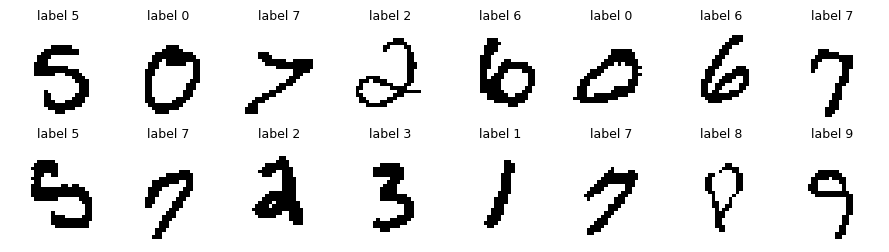

In [17]:
fig, axes = plt.subplots(2, 8, figsize=(9, 2.6))
for ax, i in zip(axes.ravel(), rng.choice(n, 16, replace=False)):
    ax.imshow(X[i].reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(f'label {y[i]}', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

The digits remain easy to read with only two pixel values, so a
model of binary images loses little of what makes a digit a digit.

**The component distribution.** A Gaussian is the wrong density for a 0/1
pixel. The natural choice is a Bernoulli per pixel: component $k$ has a vector
$\mu_k\in(0,1)^{784}$ of "ink probabilities", and the pixels are independent
*given the component*,
$$
p(x\mid z=k)=\prod_{j=1}^{784}\mu_{kj}^{\,x_j}(1-\mu_{kj})^{1-x_j},
\qquad
\log p(x\mid z=k)=\sum_j\bigl[x_j\log\mu_{kj}+(1-x_j)\log(1-\mu_{kj})\bigr].
$$
The log likelihood is linear in $x$, so for all images and all components at
once it is a single matrix product:
$$
\log p(x_i\mid z=k)=x_i^\top\bigl[\log\mu_k-\log(1-\mu_k)\bigr]+\textstyle\sum_j\log(1-\mu_{kj}).
$$
The cell implements this formula, checks it against a direct pixel-by-pixel
loop for one image, and prints the log likelihood of the first training image
under the "average digit" template $\mu=\bar x$. Look at the size of that
number.

In [18]:
def log_bernoulli(X, mu):
    """log p(x_i | z = k) for every image i and component k: an (n, K) array."""
    return X @ (np.log(mu) - np.log1p(-mu)).T + np.log1p(-mu).sum(axis=1)

average = X.mean(axis=0).clip(1e-3, 1 - 1e-3)[None, :]      # one template: the mean image
fast = log_bernoulli(X[:1], average)[0, 0]
slow = sum(np.log(average[0, j]) if X[0, j] else np.log(1 - average[0, j]) for j in range(d))
print(f'log p(x_1 | average template): matrix form {fast:.4f}, pixel loop {slow:.4f}')
print(f'as a probability: {np.exp(fast):.3e}')
assert abs(fast - slow) < 1e-8

log p(x_1 | average template): matrix form -214.7697, pixel loop -214.7697
as a probability: 5.330e-94


The two computations agree, and the number is $-214.8$ nats: this one
binary image has probability about $5\times10^{-94}$ under the average
template. (A nat is the unit of a natural logarithm, as in Part A: a log
probability of $-214.8$ nats is a probability of $e^{-214.8}$. Dividing by
the 784 pixels gives 0.27 nats per pixel, against $\ln2\approx0.69$ nats for
a pixel coded as a fair coin; with $\log_2$ the same numbers are in bits.) Such tiny probabilities are normal, since there are
$2^{784}$ possible images, but they decide how the E-step has to be computed.

## B2. The mixture and its posterior

The model is the lecture's mixture with Bernoulli components,
$$
\Pr(Z_i=k)=\pi_k,\qquad x_i\mid Z_i=k\sim\prod_j\mathrm{Bernoulli}(\mu_{kj}),
\qquad p_\theta(x)=\sum_{k=1}^K\pi_k\,p(x\mid z=k),
$$
with $\theta=(\pi_k,\mu_k)_{k=1}^K$: $K\cdot784$ ink probabilities plus $K-1$
free weights, so $7{,}849$ numbers for $K=10$. The posterior is Bayes' rule,
exactly as on the slides,
$$
\gamma_{ik}=\frac{\pi_k\,p(x_i\mid z=k)}{\sum_\ell\pi_\ell\,p(x_i\mid z=\ell)}.
$$

**By hand, on three pixels.** Take $x=(1,0,1)$, equal weights, and two
templates $\mu_1=(.9,.2,.8)$ and $\mu_2=(.3,.6,.4)$. Then
$w_1=\tfrac12(.9)(.8)(.8)=.288$ and $w_2=\tfrac12(.3)(.4)(.4)=.024$, so
$\gamma_1=.288/.312\approx.923$. The cell reproduces this with the
`log_bernoulli` function and a log-sum-exp.

In [19]:
from scipy.special import logsumexp

x_small = np.array([[1.0, 0.0, 1.0]])
mu_small = np.array([[0.9, 0.2, 0.8], [0.3, 0.6, 0.4]])
log_joint = np.log([0.5, 0.5]) + log_bernoulli(x_small, mu_small)
gamma_small = np.exp(log_joint - logsumexp(log_joint, axis=1, keepdims=True))
print('joint weights w_k:', np.round(np.exp(log_joint), 4))
print('posterior gamma  :', np.round(gamma_small, 4))
assert np.allclose(np.exp(log_joint), [0.288, 0.024]) and abs(gamma_small[0, 0] - 0.288 / 0.312) < 1e-12

joint weights w_k: [[0.288 0.024]]
posterior gamma  : [[0.9231 0.0769]]


The code returns $w=(.288,.024)$ and $\gamma=(.923,.077)$, the
numbers computed by hand.

**Why log space is required.** With 784 pixels the joint weights
$\pi_k\,p(x_i\mid z=k)$ are numbers like $e^{-240}$. The next cell evaluates
the posterior of the first training image under ten templates (ten random
training images, blended half-and-half with the average image) two ways: by
exponentiating the joint weights directly in single precision, and with the
log-sum-exp of the lecture. Look at what the direct method returns.

In [20]:
templates = (0.5 * X[rng.choice(n, 10, replace=False)] + 0.5 * X.mean(axis=0)).clip(0.05, 0.95)
a = np.log(np.full(10, 0.1)) + log_bernoulli(X[:1], templates)[0]      # a_k = log pi_k + log p(x|k)
direct = np.exp(a.astype(np.float32))
print('log joint weights a_k:', np.round(a, 1))
print('direct exp in float32:', direct, ' sum =', direct.sum())
m = a.max()
stable = np.exp(a - m) / np.exp(a - m).sum()
print('log-sum-exp posterior:', np.round(stable, 4))
assert direct.sum() == 0 and abs(stable.sum() - 1) < 1e-12

log joint weights a_k: [-246.1 -282.  -259.8 -289.9 -283.1 -249.1 -251.4 -262.7 -275.3 -279.7]
direct exp in float32: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]  sum = 0.0
log-sum-exp posterior: [0.9475 0.     0.     0.     0.     0.0477 0.0048 0.     0.     0.    ]


Every joint weight is below $e^{-246}$, which single precision
rounds to exactly zero, so the direct formula would divide $0$ by $0$.
Subtracting the largest $a_k$ first, the lecture's stable log-sum-exp, gives a
valid posterior. It also shows something new about images: the $a_k$ differ by
tens of nats, so even this image, which splits its posterior as
$(.948,.048,.005)$ over three templates, puts essentially zero on the other
seven.
With 784 pieces of evidence, the data overwhelm the prior much faster than
they did with two measurements per car.

## B3. The M-step, and why it needs smoothing

Holding $\gamma$ fixed, the expected complete-data log likelihood
$Q(\theta)=\sum_{i,k}\gamma_{ik}\bigl[\log\pi_k+\log p(x_i\mid z=k)\bigr]$
separates by component and by pixel. Setting derivatives to zero gives the
lecture's updates with $N_k=\sum_i\gamma_{ik}$:
$$
\pi_k^{\rm new}=\frac{N_k}{n},
\qquad
\mu_{kj}^{\rm new}=\frac{\sum_i\gamma_{ik}x_{ij}}{N_k}.
$$
The template is a weighted average image, the Bernoulli counterpart of the
weighted mean $\mu_k^{\rm new}$ in the slides.

**The failure.** If no image with weight in component $k$ has pixel $j$ on,
then $\mu_{kj}=0$, and any later image with that pixel on gets
$\log p(x\mid z=k)=\log 0=-\infty$. This is the Bernoulli version of the
covariance collapse in the lecture: a parameter reaches the boundary of its
range and the likelihood stops being finite. The fix plays the role of the
variance floor. Add $a$ pseudo-images with the pixel on and $a$ with it off,
$$
\mu_{kj}^{\rm new}=\frac{\sum_i\gamma_{ik}x_{ij}+a}{N_k+2a},
$$
which is the maximum a posteriori update under a $\mathrm{Beta}(1+a,1+a)$
prior on each $\mu_{kj}$ and keeps every template inside $(0,1)$. We use
$a=1$.

The cell makes the failure concrete with hard labels: it fits one template per
digit class on the training set by plain averaging ($a=0$), then scores the
test images under their own class template.

In [21]:
raw = np.stack([X[y == c].mean(axis=0) for c in range(10)])          # a = 0
smoothed = np.stack([(X[y == c].sum(axis=0) + 1) / ((y == c).sum() + 2) for c in range(10)])
print('pixels with mu exactly 0, per class template:', (raw == 0).sum(axis=1))

def log_bernoulli_exact(x, mu):
    """Pixel-by-pixel log likelihood that uses only the terms x actually selects."""
    with np.errstate(divide='ignore'):
        return np.where(x == 1, np.log(mu), np.log1p(-mu)).sum()

own_raw = np.array([log_bernoulli_exact(X_test[i], raw[y_test[i]]) for i in range(len(X_test))])
own_smooth = log_bernoulli(X_test, smoothed)[np.arange(len(X_test)), y_test]
print(f'test images with log p = -inf under the unsmoothed template: {np.isneginf(own_raw).sum()} of {len(X_test)}')
print(f'with a = 1 every value is finite; mean {own_smooth.mean():.1f} nats per image')
assert np.isneginf(own_raw).sum() > 0 and np.isfinite(own_smooth).all()

pixels with mu exactly 0, per class template: [267 309 208 241 226 224 261 247 263 271]


test images with log p = -inf under the unsmoothed template: 32 of 10000
with a = 1 every value is finite; mean -169.8 nats per image


Pixels near the border are never on in the training images of a
class, so each class template holds between 208 and 309 exact zeros, and 32
test images put ink on one of those pixels and receive probability exactly
zero under their own class. One
pseudo-count per pixel removes every infinity at a cost that 6,000 images per
class make negligible. From here on every M-step uses $a=1$.

## B4. Run EM with $K=10$

The function below is the whole algorithm. Each iteration runs an E-step
(log joint weights, log-sum-exp, posterior) and records the log likelihood
$\ell(\theta)=\sum_i\log p_\theta(x_i)$ at the current parameters, then an
M-step with smoothing. Initialization picks $K$ random training images and
blends each half-and-half with the average image, so every component starts
near a real digit with no exact zeros.

With smoothing, what EM provably never decreases is the penalized objective
$\ell(\theta)+a\sum_{k,j}\bigl[\log\mu_{kj}+\log(1-\mu_{kj})\bigr]$, the log
posterior of $\theta$ up to a constant; the monotonicity proof of the lecture
goes through with the prior term added to $Q$. We record both. Look at how much
of the improvement arrives in the first iteration, and check the two
monotonicity asserts.

50 EM iterations on 60,000 images: 3.8 s
iteration  0: log likelihood per image  -222.04 nats (0.409 bits per pixel)
iteration  1: log likelihood per image  -175.18 nats (0.322 bits per pixel)
iteration  2: log likelihood per image  -172.09 nats (0.317 bits per pixel)
iteration  3: log likelihood per image  -170.69 nats (0.314 bits per pixel)
iteration  5: log likelihood per image  -168.06 nats (0.309 bits per pixel)
iteration 10: log likelihood per image  -165.58 nats (0.305 bits per pixel)
iteration 20: log likelihood per image  -165.44 nats (0.304 bits per pixel)
iteration 50: log likelihood per image  -165.32 nats (0.304 bits per pixel)


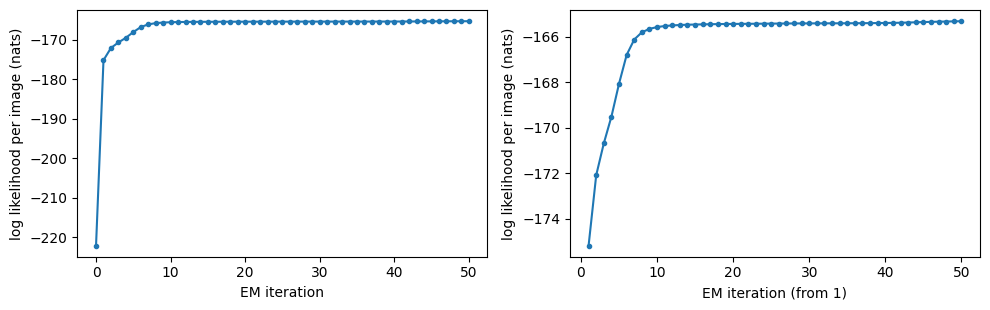

In [22]:
def e_step(X, pi, mu):
    log_joint = np.log(pi) + log_bernoulli(X, mu)
    log_px = logsumexp(log_joint, axis=1)                 # log p_theta(x_i)
    return np.exp(log_joint - log_px[:, None]), log_px

def m_step(X, gamma, a=1.0):
    counts = gamma.sum(axis=0)                            # N_k
    return counts / len(X), (gamma.T @ X + a) / (counts[:, None] + 2 * a)

def bernoulli_em(X, K, seed, steps=50, a=1.0, keep=()):
    rng = np.random.default_rng(seed)
    mu = (0.5 * X[rng.choice(len(X), K, replace=False)] + 0.5 * X.mean(axis=0)).clip(0.05, 0.95)
    pi = np.full(K, 1 / K)
    loglik, objective, snapshots = [], [], {}
    for t in range(steps + 1):
        gamma, log_px = e_step(X, pi, mu)
        loglik.append(log_px.sum())
        objective.append(log_px.sum() + a * (np.log(mu) + np.log1p(-mu)).sum())
        if t in keep:
            snapshots[t] = mu.copy()
        if t == steps:
            break
        pi, mu = m_step(X, gamma, a)
    return dict(pi=pi, mu=mu, gamma=gamma, loglik=np.array(loglik),
                objective=np.array(objective), snapshots=snapshots)

K = 10
start = time.time()
fit = bernoulli_em(X, K, seed=SEED, steps=50, keep=(0, 1, 3, 10, 50))
print(f'50 EM iterations on {n:,} images: {time.time() - start:.1f} s')
per_image = fit['loglik'] / n
for t in [0, 1, 2, 3, 5, 10, 20, 50]:
    print(f'iteration {t:2d}: log likelihood per image {per_image[t]:8.2f} nats '
          f'({-per_image[t] / d / np.log(2):.3f} bits per pixel)')
assert np.all(np.diff(fit['objective']) > -1e-6 * n)     # guaranteed by EM
assert np.all(np.diff(fit['loglik']) > -1e-6 * n)        # also holds here

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(per_image, 'o-', ms=3)
axes[0].set(xlabel='EM iteration', ylabel='log likelihood per image (nats)')
axes[1].plot(np.arange(1, 51), per_image[1:], 'o-', ms=3)
axes[1].set(xlabel='EM iteration (from 1)', ylabel='log likelihood per image (nats)')
plt.tight_layout(); plt.show()

Iteration 0 is the starting point, at $-222.0$ nats per image. One
EM iteration lifts it to $-175.2$, about 80% of the total gain, and by
iteration 10 the curve is at $-165.6$; the last 40 iterations add only $0.26$
nats more, finishing at $-165.32$ nats, or $0.304$ bits per pixel. Both
asserts pass: neither the penalized objective nor the log likelihood itself
went down at any step. For scale, the single "average digit" template of
Section B1 gave the first image $-215$ nats, and coding a pixel as a fair coin
costs one bit, so ten templates already describe each pixel with less than a
third of a bit.

**What the components look like as they are fitted.** Each template
$\mu_k$ is an image of ink probabilities, so it can be drawn. The rows of the
next figure are iterations 0, 1, 3, 10, and 50; the columns are the ten
components, labelled with their final weight $\widehat\pi_k$.

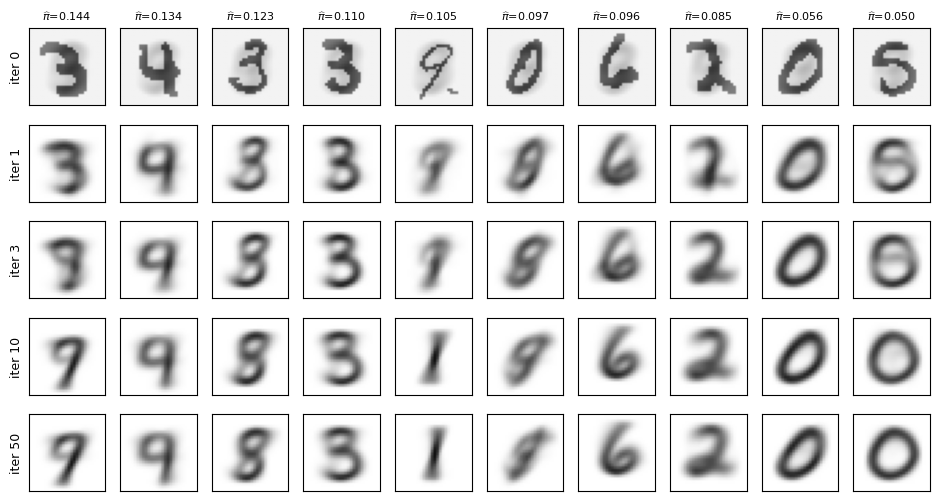

In [23]:
order = np.argsort(-fit['pi'])
fig, axes = plt.subplots(5, K, figsize=(9.5, 5.2))
for row, t in enumerate([0, 1, 3, 10, 50]):
    for col, k in enumerate(order):
        ax = axes[row, col]
        ax.imshow(fit['snapshots'][t][k].reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(f'iter {t}', fontsize=9)
        if row == 0:
            ax.set_title(f'$\\widehat\\pi$={fit["pi"][k]:.3f}', fontsize=8)
plt.tight_layout(); plt.show()

At iteration 0 every template is a blurred copy of one random training
image. After a single iteration each has become an average of the images that
claimed it, and the identity of a template can change on the way: the column
that started as a 4 is a 9 from iteration 1, and the second column from the
right turns from a 5 into a 0 by iteration 10. Between iterations 10 and 50
the pictures barely move, matching the flat end of the likelihood curve. The
final set holds two 0s, a 1, 2, 3, 6, 7, 8, 9, and one slanted template that
mixes 8 and 9. There is no 4 and no 5 template: with only ten components the
likelihood prefers two kinds of 0 to a separate 4, because 4 and 9 share most
of their ink.

## B5. The ELBO identity, checked on 60,000 images

The lecture proved that for any distributions $q_i$ over the components,
$$
\log p_\theta(x_i)=\mathcal L(q_i,\theta)+D_{\rm KL}\bigl(q_i\,\|\,p_\theta(z\mid x_i)\bigr),
\qquad
\mathcal L(q_i,\theta)=\sum_k q_{ik}\bigl[\log\pi_k+\log p(x_i\mid z=k)-\log q_{ik}\bigr].
$$
The cell evaluates both sides at the fitted $\theta$ for three choices of $q$:
the posterior $\gamma$ (the E-step), the hard label $\arg\max_k\gamma_{ik}$
(what $K$-means would use), and the uniform distribution over components.
Look at the gap column: it should be zero for the posterior and equal to the
KL divergence in the other two rows.

In [24]:
log_joint = np.log(fit['pi']) + log_bernoulli(X, fit['mu'])
gamma, log_px = e_step(X, fit['pi'], fit['mu'])
log_gamma = log_joint - log_px[:, None]     # log posterior, kept in log space

def elbo(q):
    with np.errstate(divide='ignore', invalid='ignore'):
        terms = np.where(q > 0, q * (log_joint - np.log(q)), 0.0)
    return terms.sum(axis=1)

def kl_to_posterior(q):
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(q > 0, q * (np.log(q) - log_gamma), 0.0).sum(axis=1)

choices = {'posterior gamma (E-step)': gamma,
           'hard label argmax gamma': np.eye(K)[gamma.argmax(axis=1)],
           'uniform 1/K': np.full_like(gamma, 1 / K)}
rows = []
for name, q in choices.items():
    bound, divergence = elbo(q), kl_to_posterior(q)
    rows.append({'q': name, 'sum log p(x)': log_px.sum(), 'sum ELBO': bound.sum(),
                 'gap': log_px.sum() - bound.sum(), 'sum KL(q || posterior)': divergence.sum()})
    assert np.allclose(log_px, bound + divergence, atol=1e-6)
display(pd.DataFrame(rows).round(2))

,q,sum log p(x),sum ELBO,gap,sum KL(q || posterior)
0,posterior gamma (E-step),-9919125.76,-9919125.76,0.00,-0.00
1,hard label argmax gamma,-9919125.76,-9919807.27,681.50,681.50
2,uniform 1/K,-9919125.76,-16855238.44,6936112.68,6936112.68


With $q=\gamma$ the bound equals $\sum_i\log p_\theta(x_i)=-9{,}919{,}126$
nats to every printed digit, so the gap is zero: this is the E-step making the
bound tight, as on the slides. With hard labels the bound is lower by $681.5$
nats in total, and the KL column reports exactly that number; spread over
60,000 images it is about $0.01$ nats each, because almost every posterior is
already nearly one-hot. The uniform $q$ ignores the evidence, and its gap of
$6.9$ million nats, about 116 nats per image, is again exactly its KL to the
posterior. The assert checks the identity separately for each of the 60,000 images.

## B6. What the components found

The model never saw a label. The cell lists each component's weight
$\widehat\pi_k$ and effective count $N_k$, then cross-tabulates the
largest-posterior component of every training image against its true digit,
and computes **purity**: the share of images whose component's most common
digit is their own digit.

In [25]:
hard = gamma.argmax(axis=1)
table = pd.crosstab(pd.Series(hard, name='component'), pd.Series(y, name='digit'))
table = table.loc[order]
summary = pd.DataFrame({'pi_hat': fit['pi'][order].round(3), 'N_k': gamma.sum(axis=0)[order].round(0),
                        'majority digit': table.idxmax(axis=1).values,
                        'share of majority': (table.max(axis=1) / table.sum(axis=1)).round(2).values},
                       index=order)
display(summary)
display(table)
purity = table.max(axis=1).sum() / n
print(f'purity: {purity:.3f}')
print(f'images whose largest posterior is below 0.99: {(gamma.max(axis=1) < 0.99).mean():.3f}')
print(f'images whose largest posterior is below 0.6: {(gamma.max(axis=1) < 0.6).sum()}')

,pi_hat,N_k,majority digit,share of majority
5,0.144,8655.0,7,0.46
4,0.134,8061.0,4,0.38
0,0.123,7367.0,8,0.45
3,0.110,6593.0,3,0.53
7,0.105,6252.0,1,0.84
1,0.097,5830.0,5,0.24
9,0.096,5751.0,6,0.87
8,0.085,5097.0,2,0.90
2,0.056,3364.0,0,0.74
6,0.050,3028.0,0,0.93


digit,0,1,2,3,4,5,6,7,8,9
component,,,,,,,,,,
5,1,5,14,42,1754,132,1,3972,102,2628
4,10,19,126,180,3034,223,34,1615,156,2664
0,268,42,198,1594,41,1694,100,19,3309,113
3,159,9,374,3468,1,1469,31,13,1006,64
7,0,5271,106,209,50,34,137,161,173,105
1,98,1346,125,157,737,1409,291,422,946,303
9,87,30,312,61,111,96,5019,4,32,2
8,5,20,4572,264,50,18,75,34,42,12
2,2484,0,116,147,54,292,172,12,57,28


purity: 0.589
images whose largest posterior is below 0.99: 0.064
images whose largest posterior is below 0.6: 334


Purity is $0.589$: for 59% of the training images, the component they
fall in is mostly made of their own digit. Some components are almost pure,
such as the 0s (93% and 74%), the 2s (90%), the 6s (87%), and the 1s (84%).
Others are shared by digits that look alike once the strokes are blurred: the
component whose majority is 7 also holds 2,628 nines and 1,754 fours, and the
"4" component holds nearly as many 9s (2,664) as 4s (3,034). The slanted
component has a majority digit of 5, but only 24% of its images are 5s. The
model is finding *styles of ink*, and its components need not line up with
the classes we happen to know about, which is the warning at the end of the
lecture. As the E-step section predicted, the posteriors are sharp: only 6.4%
of the images have a largest posterior below $0.99$, and 334 below $0.6$.

**The ambiguous images.** The next cell shows the twelve training
images with the smallest largest posterior, each above a bar chart of its
$\gamma_{i\cdot}$ over the components (in the same order as the table, with
the majority digit on the axis).

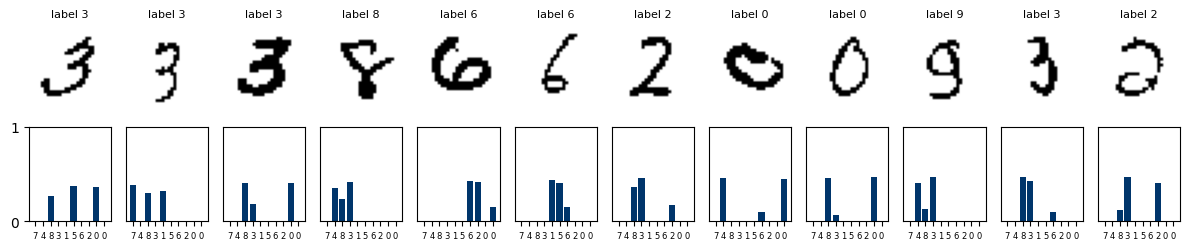

In [26]:
ambiguous = np.argsort(gamma.max(axis=1))[:12]
fig, axes = plt.subplots(2, 12, figsize=(12, 2.6), gridspec_kw={'height_ratios': [1.2, 1]})
for col, i in enumerate(ambiguous):
    axes[0, col].imshow(X[i].reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
    axes[0, col].set_title(f'label {y[i]}', fontsize=8); axes[0, col].axis('off')
    axes[1, col].bar(range(K), gamma[i, order], color='#00356B')
    axes[1, col].set(ylim=(0, 1), yticks=[] if col else [0, 1])
    axes[1, col].set_xticks(range(K), summary['majority digit'].astype(str), fontsize=6)
plt.tight_layout(); plt.show()

These are images that sit between templates. The thin 3s split their
posterior between the 3 template, the 8 template, and the 2 template; the 6s
split between the two 6-like components; the round 0s split between the two 0
components. Each split is close to even, so a single extra pixel of ink would
move the hard label. A hard assignment hides exactly these images, and the
posterior keeps them.

**Restarts and label switching.** The likelihood is nonconvex, and the
lecture warned that runs from different starts can stop at different heights,
with component numbers that mean nothing across runs. The cell reruns EM from
four further seeds (30 iterations each) and reports each final log likelihood
per image, and which component number ended up holding the 0s and the 1s.

In [27]:
rows = []
for run in range(1, 5):
    other = bernoulli_em(X, K, seed=SEED + run, steps=30)
    labels_other = other['gamma'].argmax(axis=1)
    rows.append({'seed': SEED + run, 'final log lik per image': other['loglik'][-1] / n,
                 'component holding most 0s': np.bincount(labels_other[y == 0], minlength=K).argmax(),
                 'component holding most 1s': np.bincount(labels_other[y == 1], minlength=K).argmax(),
                 'components that are mostly 1s': int(sum(pd.crosstab(labels_other, y).idxmax(axis=1) == 1))})
rows.insert(0, {'seed': SEED, 'final log lik per image': fit['loglik'][30] / n,
                'component holding most 0s': np.bincount(hard[y == 0], minlength=K).argmax(),
                'component holding most 1s': np.bincount(hard[y == 1], minlength=K).argmax(),
                'components that are mostly 1s': int(sum(table.idxmax(axis=1) == 1))})
restarts = pd.DataFrame(rows)
display(restarts.round(2))
assert restarts['final log lik per image'].max() - restarts['final log lik per image'].min() > 0.05

,seed,final log lik per image,component holding most 0s,component holding most 1s,components that are mostly 1s
0,26519,-165.41,6,7,1
1,26520,-165.16,2,0,2
2,26521,-165.32,2,0,2
3,26522,-165.48,7,6,2
4,26523,-164.94,8,9,2


Every run climbs, and the five runs stop between $-165.48$ and $-164.94$
nats per image. A gap of $0.54$ nats per image is about $32{,}000$ nats over
the training set, so these are genuinely different local maxima of the
likelihood. They also divide the digits differently: one run spends a single
component on the 1s, the other four spend two. The component numbers carry
no meaning across runs: the 0s land in component 6, 2, 2, 7, and 8 in the five
runs. Comparing runs by final likelihood, and never by component number, is
the rule from the lecture's restart slide.

## B7. How many components?

A larger $K$ always raises the training likelihood, so we score on the
10,000 test images, which played no part in fitting. The cell fits
$K=5,10,20,40$ (one start each, 40 iterations) and reports the average
log likelihood per image on both sets, together with the smallest effective
count $N_k$.

In [28]:
sweep, fits = [], {}
for K_try in [5, 10, 20, 40]:
    start = time.time()
    fits[K_try] = f = bernoulli_em(X, K_try, seed=SEED, steps=40)
    test_ll = logsumexp(np.log(f['pi']) + log_bernoulli(X_test, f['mu']), axis=1).mean()
    sweep.append({'K': K_try, 'parameters': K_try * d + K_try - 1,
                  'train log lik per image': f['loglik'][-1] / n, 'test log lik per image': test_ll,
                  'smallest N_k': f['gamma'].sum(axis=0).min(), 'seconds': time.time() - start})
sweep = pd.DataFrame(sweep)
display(sweep.round(2))
assert sweep['test log lik per image'].is_monotonic_increasing

,K,parameters,train log lik per image,test log lik per image,smallest N_k,seconds
0,5,3924,-178.69,-178.00,7858.02,5.87
1,10,7849,-165.40,-165.09,2990.77,7.59
2,20,15699,-152.66,-152.38,1782.29,4.60
3,40,31399,-143.40,-143.41,723.10,6.11


The test log likelihood improves at every step, from $-178.0$ at $K=5$
to $-143.4$ nats per image at $K=40$, and the test values track the training
values within $0.7$ nats: with 60,000 images, even the 31,399 parameters of
$K=40$ are far from overfitting. The smallest component still holds 723
effective images at $K=40$, far from the near-empty components of the Auto
sweep. The data can support many more components than there are digits,
which is a reminder that the best density and the most meaningful set of
groups are different targets.

The cell below draws the 40 templates of the $K=40$ fit, sorted by
weight. Look for digits that now own several components.

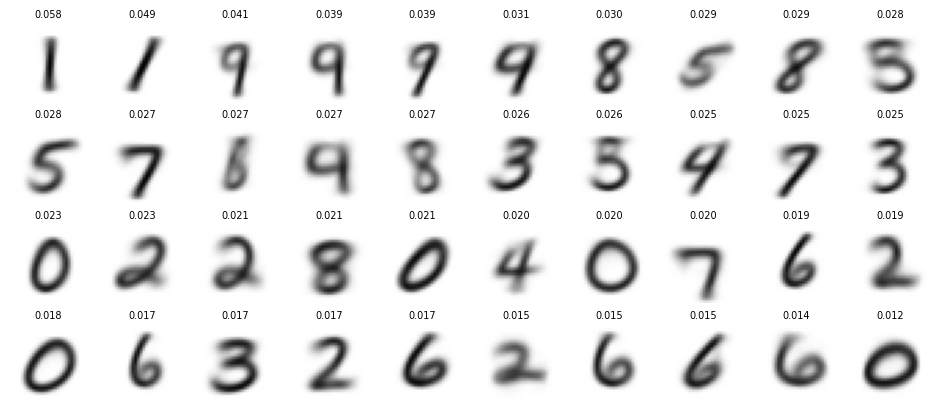

In [29]:
f40 = fits[40]
order40 = np.argsort(-f40['pi'])
fig, axes = plt.subplots(4, 10, figsize=(9.5, 4.2))
for ax, k in zip(axes.ravel(), order40):
    ax.imshow(f40['mu'][k].reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(f'{f40["pi"][k]:.3f}', fontsize=7); ax.axis('off')
plt.tight_layout(); plt.show()

With 40 components the digits split by *style*: there are separate
upright and slanted 1s, at least five 9s, several 0s of different widths, and
6s with long and short stems. Each template is still a blurred average, and
every image must pick one of these 40 averages.

## B8. Generating images, and what a discrete code cannot do

The mixture is a generative model: draw $z\sim\mathrm{Categorical}(\pi)$,
then draw every pixel independently, $x_j\sim\mathrm{Bernoulli}(\mu_{zj})$.
The cell draws 20 images from the $K=10$ fit. The top row shows the template
each draw came from, the bottom row the sampled image.

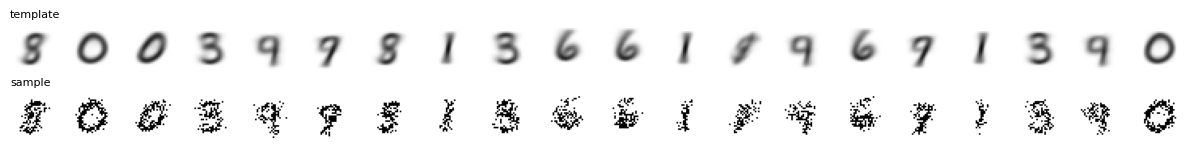

distinct templates used by the 20 draws: 9


In [30]:
draw_rng = np.random.default_rng(SEED + 100)
z = draw_rng.choice(K, size=20, p=fit['pi'])
samples = (draw_rng.random((20, d)) < fit['mu'][z]).astype(float)
fig, axes = plt.subplots(2, 20, figsize=(12, 1.6))
for col in range(20):
    axes[0, col].imshow(fit['mu'][z[col]].reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
    axes[1, col].imshow(samples[col].reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
    axes[0, col].axis('off'); axes[1, col].axis('off')
axes[0, 0].set_title('template', fontsize=8, loc='left'); axes[1, 0].set_title('sample', fontsize=8, loc='left')
plt.tight_layout(); plt.show()
print('distinct templates used by the 20 draws:', len(set(z)))

The samples are recognizably drawn from their templates, and they look
nothing like handwriting. Given the component, every pixel is an independent
coin flip, so the ink comes out as scattered dots around the blurred
template: the model has no way to say that neighbouring pixels in a stroke are
on together. And a sample can only ever be one of $K$ templates plus noise:
20 draws used 9 of the 10. Making $K$ larger adds more templates, without ever
producing a stroke that bends a little further than one of them.

Both limitations point at the same fix. Replace the discrete code
$z\in\{1,\dots,K\}$ by a **continuous** code $z\in\mathbb R^r$, and the template
$\mu_z$ by a neural network $f_\theta(z)$ that maps every code to its own
image. Neighbouring codes then give neighbouring shapes, and the continuum of
codes gives a continuum of images. The price, as the end of the lecture says,
is that the posterior $p_\theta(z\mid x)$ loses its closed form, so the
E-step has to be learned. That is the variational autoencoder of
Lecture 17.

**The number to carry into Lecture 17.** On the binarized test set
the mixture achieves the log likelihoods below, in nats per image. The
variational autoencoder notebook of Lecture 17 reports its negative ELBO on the
same binarized test images. Since the ELBO is a lower bound, a VAE whose
$-$ELBO is smaller than these numbers is certainly a better density model.

In [31]:
for K_try in [10, 40]:
    value = sweep.loc[sweep.K == K_try, 'test log lik per image'].item()
    print(f'K = {K_try:2d}: test log likelihood {value:7.2f} nats per image  '
          f'(negative log likelihood {-value:6.2f})')
print(f'notebook run time: {time.time() - NOTEBOOK_START:.0f} s')

K = 10: test log likelihood -165.09 nats per image  (negative log likelihood 165.09)
K = 40: test log likelihood -143.41 nats per image  (negative log likelihood 143.41)
notebook run time: 59 s


## Summary of Part B

The mixture of Bernoullis is the lecture's mixture with a different
component density, and EM keeps its form: a Bayes-rule E-step computed in log
space, and an M-step in which each template is a posterior-weighted average
image. Log space is required: the joint weights of a 784-pixel image are
around $e^{-250}$, which single precision rounds to zero. Smoothing with one
pseudo-count per pixel plays the role of the variance floor; without it, 32 of
the 10,000 test images get probability exactly zero under their own class
template. With $K=10$, one EM iteration brings the log likelihood from $-222$
to $-175$ nats per image, and 50 iterations reach $-165.3$, with no step going
down. The ELBO identity holds image by image: it is tight at the posterior,
and the gap for hard labels (681 nats in total) or a uniform $q$ (116 nats per
image) equals the KL divergence exactly. The components reach a purity of
0.59 against labels they never saw: 0, 1, 2, and 6 are found cleanly, while 4,
7, and 9 share components. Restarts end at different likelihoods with
unrelated component numbers. Held-out likelihood keeps improving up to $K=40$
($-143.4$ nats per test image), as the templates split each digit into
styles. Sampling shows the limits of a discrete code with independent pixels,
dotted ink around one of $K$ blurred templates, and that is the motivation for
the continuous code and neural decoder of Lecture 17.

## Try It: Part B

For each change, write down a prediction before rerunning the cells.

1. **No smoothing.** In Section B4, call `bernoulli_em(X, K, seed=SEED, a=0.0)`.
   Does the training likelihood stay finite? Score the test set with the
   result: how many test images now get $-\infty$?
2. **Heavy smoothing.** Set `a=1000`. Predict what the templates look like
   when every component carries 2,000 pseudo-images.
3. **Uniform initialization.** Replace the initialization by
   `mu = np.full((K, d), 0.5) + 0.01 * rng.standard_normal((K, d))`. The
   templates now start almost identical. How many iterations pass before they
   differ visibly, and where does the likelihood end?
4. **Fewer data.** Fit $K=40$ on the first 2,000 training images only. Predict
   whether test likelihood still improves from $K=20$ to $K=40$, and look at
   the smallest $N_k$.
5. **Grey levels.** The binarization threshold is 128. Try 64 and 192. Which
   digits change their components, and why does the log likelihood per image
   move even though the model is unchanged?

In [32]:
print(f'notebook finished in {time.time() - NOTEBOOK_START:.1f} s')

notebook finished in 59.1 s
